In [9]:
import pandas as pd
import numpy as np

In [10]:
df=pd.read_csv("Oasis Infobyte/messy_retail_sales_dataset.csv")
df.head()

,Order_ID,Order_Date,Customer_Name,Age,Gender,City,Product,Category,Quantity,Unit_Price,Discount,Total_Amount,Payment_Method,Order_Status,Customer_Email
0,ORD-0001,2025-02-27,Sneha Rao,26,NaN,NaN,Mobile,FURNITURE,NaN,54999,0.1,54999.0,UPI,Pending,customer1gmail.com
1,ORD-0002,2025-09-16,NaN,unknown,FEMALE,Chennai,Laptop,Furniture,-2,NaN,NaN,2495.0,Credit Card,Pending,customer2gmail.com
2,ORD-0003,2025-06-22,Ananya Iyer,NaN,Male,PUNE,laptop,Electronics,NaN,499,0.15,NaN,Credit Card,NaN,not_available
3,ORD-0004,2025-07-05,Aarav Shah,NaN,Male,Bengaluru,Mobile,electronics,5,NaN,10%,-100.0,NaN,Cancelled,customer4gmail.com
4,ORD-0005,09/07/2025,Priya Mehta,58,FEMALE,Bengaluru,Headphones,electronics,NaN,799,10%,-100.0,cash,PENDING,customer5gmail.com


In [11]:
df.shape

(123, 15)

In [12]:
df.info

<bound method DataFrame.info of      Order_ID  Order_Date    Customer_Name      Age    Gender       City  \
0    ORD-0001  2025-02-27        Sneha Rao       26       NaN        NaN   
1    ORD-0002  2025-09-16              NaN  unknown   FEMALE     Chennai   
2    ORD-0003  2025-06-22      Ananya Iyer      NaN      Male      PUNE    
3    ORD-0004  2025-07-05       Aarav Shah      NaN      Male  Bengaluru   
4    ORD-0005  09/07/2025      Priya Mehta       58   FEMALE   Bengaluru   
..        ...         ...              ...      ...       ...        ...   
118  ORD-0119  2025-04-13       Vikram Das  unknown      Male  Hyderabad   
119  ORD-0120  2025-03-31        Sneha Rao  unknown      Male  Hyderabad   
120  ORD-0005  09/07/2025      Priya Mehta       58   FEMALE   Bengaluru   
121  ORD-0019  07-26-2025    riya sharma         20      male        NaN   
122  ORD-0051  2025-02-28    riya sharma         58    Female      Delhi   

        Product     Category Quantity Unit_Price Discou

In [15]:
print("\nColumn Names:")
print(df.columns.tolist())


Column Names:
['Order_ID', 'Order_Date', 'Customer_Name', 'Age', 'Gender', 'City', 'Product', 'Category', 'Quantity', 'Unit_Price', 'Discount', 'Total_Amount', 'Payment_Method', 'Order_Status', 'Customer_Email']


In [16]:
null_report=pd.DataFrame({"Null Count":df.isnull().sum(),"Null Percentage":(df.isnull().sum()/len(df))*100})
print(null_report)

                Null Count  Null Percentage
Order_ID                 0         0.000000
Order_Date               0         0.000000
Customer_Name           11         8.943089
Age                     18        14.634146
Gender                  20        16.260163
City                    17        13.821138
Product                 11         8.943089
Category                17        13.821138
Quantity                17        13.821138
Unit_Price              21        17.073171
Discount                37        30.081301
Total_Amount            39        31.707317
Payment_Method           7         5.691057
Order_Status            29        23.577236
Customer_Email          27        21.951220


In [17]:
duplicate_count=df.duplicated().sum()
print("Total Duplicated Rows:",duplicate_count)

Total Duplicated Rows: 3


In [19]:
df[df.duplicated(keep=False)]

,Order_ID,Order_Date,Customer_Name,Age,Gender,City,Product,Category,Quantity,Unit_Price,Discount,Total_Amount,Payment_Method,Order_Status,Customer_Email
4,ORD-0005,09/07/2025,Priya Mehta,58,FEMALE,Bengaluru,Headphones,electronics,NaN,799,10%,-100.0,cash,PENDING,customer5gmail.com
18,ORD-0019,07-26-2025,riya sharma,20,male,NaN,Mouse,Accessories,1,-999,0.05,-100.0,Credit Card,Pending,NaN
50,ORD-0051,2025-02-28,riya sharma,58,Female,Delhi,NaN,Accessories,1,15999,0.15,15999.0,upi,completed,not_available
120,ORD-0005,09/07/2025,Priya Mehta,58,FEMALE,Bengaluru,Headphones,electronics,NaN,799,10%,-100.0,cash,PENDING,customer5gmail.com
121,ORD-0019,07-26-2025,riya sharma,20,male,NaN,Mouse,Accessories,1,-999,0.05,-100.0,Credit Card,Pending,NaN
122,ORD-0051,2025-02-28,riya sharma,58,Female,Delhi,NaN,Accessories,1,15999,0.15,15999.0,upi,completed,not_available


In [21]:
df.dtypes

Order_ID              str
Order_Date            str
Customer_Name         str
Age                   str
Gender                str
City                  str
Product               str
Category              str
Quantity              str
Unit_Price            str
Discount              str
Total_Amount      float64
Payment_Method        str
Order_Status          str
Customer_Email        str
dtype: object

In [22]:
for col in ['Age', 'Quantity', 'Unit_Price', 'Total_Amount']:
    invalid = pd.to_numeric(df[col], errors='coerce').isna() & df[col].notna()

    print(col, ":", invalid.sum(), "invalid values")

Age : 28 invalid values
Quantity : 19 invalid values
Unit_Price : 22 invalid values
Total_Amount : 0 invalid values


In [24]:
# Convert columns into numbers
df['Age'] = pd.to_numeric(df['Age'], errors='coerce')
df['Quantity'] = pd.to_numeric(df['Quantity'], errors='coerce')
df['Unit_Price'] = pd.to_numeric(
    df['Unit_Price'].astype(str).str.replace('Rs. ', '', regex=False),
    errors='coerce'
)
df['Total_Amount'] = pd.to_numeric(df['Total_Amount'], errors='coerce')

# Check value range anomalies
print("Invalid Age:",
      ((df['Age'] < 18) | (df['Age'] > 100)).sum())

print("Invalid Quantity:",
      (df['Quantity'] <= 0).sum())

print("Negative Unit Price:",
      (df['Unit_Price'] < 0).sum())

print("Negative Total Amount:",
      (df['Total_Amount'] < 0).sum())

Invalid Age: 34
Invalid Quantity: 31
Negative Unit Price: 19
Negative Total Amount: 25


In [25]:
cleaned_df = df.copy()

In [26]:
# Mean imputation
df['Age'] = df['Age'].fillna(df['Age'].mean())

# Median imputation
df['Unit_Price'] = df['Unit_Price'].fillna(df['Unit_Price'].median())

# Mode imputation
df['Customer_Name'] = df['Customer_Name'].fillna(df['Customer_Name'].mode()[0])
df['Gender'] = df['Gender'].fillna(df['Gender'].mode()[0])
df['City'] = df['City'].fillna(df['City'].mode()[0])
df['Product'] = df['Product'].fillna(df['Product'].mode()[0])
df['Category'] = df['Category'].fillna(df['Category'].mode()[0])
df['Payment_Method'] = df['Payment_Method'].fillna(df['Payment_Method'].mode()[0])
df['Order_Status'] = df['Order_Status'].fillna(df['Order_Status'].mode()[0])

# Forward fill
df['Discount'] = df['Discount'].ffill()

# Row deletion for missing important values
df = df.dropna(subset=['Quantity', 'Total_Amount', 'Customer_Email'])

# Check remaining missing values
print(df.isnull().sum())

Order_ID          0
Order_Date        0
Customer_Name     0
Age               0
Gender            0
City              0
Product           0
Category          0
Quantity          0
Unit_Price        0
Discount          0
Total_Amount      0
Payment_Method    0
Order_Status      0
Customer_Email    0
dtype: int64


In [27]:
print("Missing Values After Cleaning:")
print(df.isnull().sum())

print("\nRemaining Rows:", len(df))

Missing Values After Cleaning:
Order_ID          0
Order_Date        0
Customer_Name     0
Age               0
Gender            0
City              0
Product           0
Category          0
Quantity          0
Unit_Price        0
Discount          0
Total_Amount      0
Payment_Method    0
Order_Status      0
Customer_Email    0
dtype: int64

Remaining Rows: 48


In [28]:
print("Total Duplicate Rows:", df.duplicated().sum())
df[df.duplicated()]

Total Duplicate Rows: 1


,Order_ID,Order_Date,Customer_Name,Age,Gender,City,Product,Category,Quantity,Unit_Price,Discount,Total_Amount,Payment_Method,Order_Status,Customer_Email
122,ORD-0051,2025-02-28,riya sharma,58.0,Female,Delhi,Mouse,Accessories,1.0,15999.0,0.15,15999.0,upi,completed,not_available


In [29]:
df = df.drop_duplicates()
print("Duplicate rows removed successfully!")

Duplicate rows removed successfully!


In [30]:
print("Duplicates After Removal:", df.duplicated().sum())
print("Final Dataset Shape:", df.shape)

Duplicates After Removal: 0
Final Dataset Shape: (47, 15)


In [31]:
df['Gender'] = df['Gender'].str.strip().str.lower()

df['Gender'] = df['Gender'].replace({
    'male': 'Male',
    'm': 'Male',
    'female': 'Female',
    'f': 'Female',
    'other': 'Other'
})

print(df['Gender'].value_counts())

Gender
Female    24
Male      15
Other      8
Name: count, dtype: int64


In [32]:
df['City'] = df['City'].str.strip().str.title()
print(df['City'].value_counts())

City
Pune         12
Mumbai       12
Hyderabad    10
Bengaluru     6
Delhi         5
Chennai       2
Name: count, dtype: int64


In [33]:
df['Product'] = df['Product'].str.strip().str.title()
print(df['Product'].value_counts())

Product
Mouse           13
Laptop           8
Keyboard         6
Mobile           5
Tablet           5
Headphones       5
Office Chair     3
Monitor          2
Name: count, dtype: int64


In [34]:
df['Category'] = df['Category'].str.strip().str.title()
print(df['Category'].value_counts())

Category
Electronics    25
Furniture      18
Accessories     4
Name: count, dtype: int64


In [36]:
df['Payment_Method'] = df['Payment_Method'].str.strip().str.title()
print(df['Payment_Method'].value_counts())

Payment_Method
Credit Card    13
Upi            13
Cash           13
Debit Card      8
Name: count, dtype: int64


In [37]:
df["Payment_Method"]=df["Payment_Method"].replace({"CASH":"Cash","UPI":"Upi","CREDIT CARD":"Credit Card","DEBIT CARD":"Debit Card"})
print(df["Payment_Method"].value_counts())

Payment_Method
Credit Card    13
Upi            13
Cash           13
Debit Card      8
Name: count, dtype: int64


In [38]:
df['Order_Date'] = pd.to_datetime(
    df['Order_Date'],
    format='mixed',
    dayfirst=True,
    errors='coerce'
)

print(df['Order_Date'].head())
print(df['Order_Date'].dtype)

1    2025-09-16
3    2025-05-07
9    2025-12-04
12   2025-04-01
14   2025-01-02
Name: Order_Date, dtype: datetime64[us]
datetime64[us]


In [39]:
df['Order_Status'] = df['Order_Status'].str.strip().str.title()
print(df['Order_Status'].value_counts())

Order_Status
Completed    27
Pending      12
Cancelled     8
Name: count, dtype: int64


In [42]:
print(df[["Customer_Name","Age","Gender","City","Product","Category","Quantity","Unit_Price","Discount","Total_Amount","Payment_Method","Order_Status","Customer_Email"]].head(10))

      Customer_Name         Age  Gender       City       Product     Category  \
1     riya sharma     55.103896  Female    Chennai        Laptop    Furniture   
3        Aarav Shah   55.103896    Male  Bengaluru        Mobile  Electronics   
9     riya sharma     -5.000000   Other       Pune        Laptop  Electronics   
12        Sneha Rao   55.103896    Male  Hyderabad  Office Chair  Accessories   
14        Sneha Rao   -5.000000    Male      Delhi       Monitor    Furniture   
15       Aarav Shah   33.000000    Male       Pune        Tablet    Furniture   
16       Kabir Khan  150.000000  Female       Pune    Headphones    Furniture   
17    riya sharma     -5.000000  Female     Mumbai        Laptop  Electronics   
19       Vikram Das   38.000000    Male       Pune        Mobile    Furniture   
20    riya sharma     -5.000000  Female  Hyderabad        Laptop  Electronics   

    Quantity  Unit_Price Discount  Total_Amount Payment_Method Order_Status  \
1       -2.0      1299.0     

In [43]:
numeric_columns = ['Age', 'Quantity', 'Unit_Price', 'Total_Amount']
df[numeric_columns].describe()

,Age,Quantity,Unit_Price,Total_Amount
count,47.000000,47.000000,47.000000,47.000000
mean,51.016303,1.957447,11256.659574,39235.617021
std,45.184477,2.653607,19307.562025,75246.930069
min,-5.000000,-2.000000,-999.000000,-100.000000
25%,25.500000,0.000000,899.000000,1398.000000
50%,55.103896,2.000000,1299.000000,3897.000000
75%,55.103896,4.000000,15999.000000,54999.000000
max,150.000000,6.000000,54999.000000,329994.000000


In [44]:
for col in numeric_columns:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower) | (df[col] > upper)]

    print("\nColumn:", col)
    print("Lower Limit:", lower)
    print("Upper Limit:", upper)
    print("Number of Outliers:", len(outliers))


Column: Age
Lower Limit: -18.905844155844157
Upper Limit: 99.50974025974025
Number of Outliers: 6

Column: Quantity
Lower Limit: -6.0
Upper Limit: 10.0
Number of Outliers: 0

Column: Unit_Price
Lower Limit: -21751.0
Upper Limit: 38649.0
Number of Outliers: 6

Column: Total_Amount
Lower Limit: -79003.5
Upper Limit: 135400.5
Number of Outliers: 5


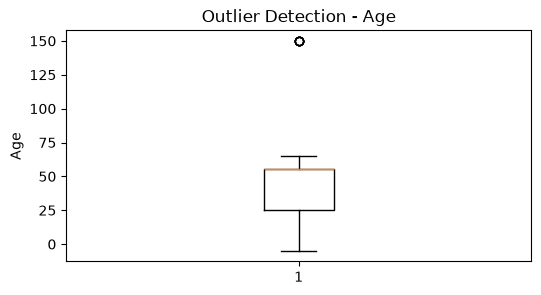

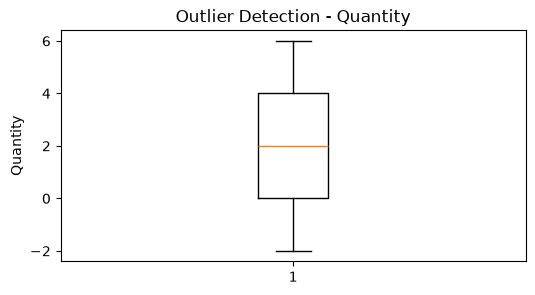

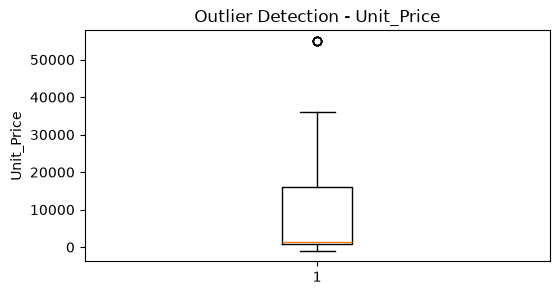

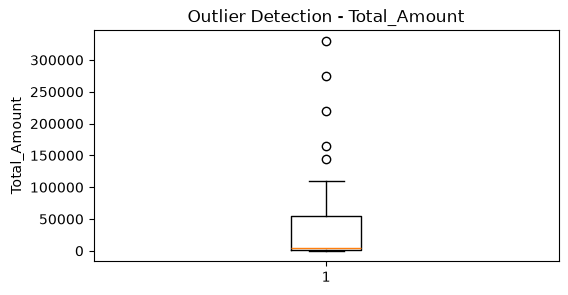

In [45]:
import matplotlib.pyplot as plt

for col in numeric_columns:
    plt.figure(figsize=(6, 3))
    plt.boxplot(df[col].dropna())
    plt.title("Outlier Detection - " + col)
    plt.ylabel(col)
    plt.show()

In [46]:
for col in ['Unit_Price', 'Total_Amount']:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    df[col] = df[col].clip(lower, upper)

print("Outliers capped successfully!")

Outliers capped successfully!


In [47]:
for col in numeric_columns:
    print(col, "Minimum:", df[col].min(),
          "Maximum:", df[col].max())

Age Minimum: -5.0 Maximum: 150.0
Quantity Minimum: -2.0 Maximum: 6.0
Unit_Price Minimum: -999.0 Maximum: 38649.0
Total_Amount Minimum: -100.0 Maximum: 135400.5


In [49]:
df.dtypes

Order_ID                     str
Order_Date        datetime64[us]
Customer_Name                str
Age                      float64
Gender                       str
City                         str
Product                      str
Category                     str
Quantity                 float64
Unit_Price               float64
Discount                     str
Total_Amount             float64
Payment_Method               str
Order_Status                 str
Customer_Email               str
dtype: object

In [50]:
# Convert Order ID into string
df['Order_ID'] = df['Order_ID'].astype('string')

# Convert Order Date into datetime
df['Order_Date'] = pd.to_datetime(df['Order_Date'], errors='coerce')

# Convert Age into integer
df['Age'] = df['Age'].round().astype('Int64')

# Convert Quantity into integer
df['Quantity'] = df['Quantity'].round().astype('Int64')

# Convert monetary columns into float
df['Unit_Price'] = df['Unit_Price'].astype(float)
df['Total_Amount'] = df['Total_Amount'].astype(float)

print("Data types corrected successfully!")

Data types corrected successfully!


In [51]:
df.head()

,Order_ID,Order_Date,Customer_Name,Age,Gender,City,Product,Category,Quantity,Unit_Price,Discount,Total_Amount,Payment_Method,Order_Status,Customer_Email
1,ORD-0002,2025-09-16,riya sharma,55,Female,Chennai,Laptop,Furniture,-2,1299.0,0.1,2495.0,Credit Card,Pending,customer2gmail.com
3,ORD-0004,2025-05-07,Aarav Shah,55,Male,Bengaluru,Mobile,Electronics,5,1299.0,10%,-100.0,Credit Card,Cancelled,customer4gmail.com
9,ORD-0010,2025-12-04,riya sharma,-5,Other,Pune,Laptop,Electronics,2,1299.0,0,2598.0,Upi,Pending,not_available
12,ORD-0013,2025-04-01,Sneha Rao,55,Male,Hyderabad,Office Chair,Accessories,-2,1299.0,10%,54999.0,Upi,Pending,not_available
14,ORD-0015,2025-01-02,Sneha Rao,-5,Male,Delhi,Monitor,Furniture,4,1299.0,0.1,135400.5,Credit Card,Completed,


In [53]:
# Load original dataset
original_df = pd.read_csv("Oasis Infobyte/messy_retail_sales_dataset.csv")
# Store original information
before_nulls = original_df.isnull().sum().sum()
before_duplicates = original_df.duplicated().sum()
before_rows = len(original_df)
print("Before Cleaning")
print("Null Values:", before_nulls)
print("Duplicate Rows:", before_duplicates)
print("Total Rows:", before_rows)

Before Cleaning
Null Values: 271
Duplicate Rows: 3
Total Rows: 123


In [54]:
after_nulls = df.isnull().sum().sum()
after_duplicates = df.duplicated().sum()
after_rows = len(df)
print("After Cleaning")
print("Null Values:", after_nulls)
print("Duplicate Rows:", after_duplicates)
print("Total Rows:", after_rows)

After Cleaning
Null Values: 0
Duplicate Rows: 0
Total Rows: 47


In [55]:
# Expected data types
expected_types = {
    'Order_ID': 'string',
    'Order_Date': 'datetime64[ns]',
    'Customer_Name': 'string',
    'Age': 'Int64',
    'Gender': 'string',
    'City': 'string',
    'Product': 'string',
    'Category': 'string',
    'Quantity': 'Int64',
    'Unit_Price': 'float64',
    'Total_Amount': 'float64',
    'Payment_Method': 'string',
    'Order_Status': 'string',
    'Customer_Email': 'string'}
correct = 0
for col, dtype in expected_types.items():
    if col in df.columns and str(df[col].dtype) == dtype:
        correct += 1
print("Correct Data Types:", correct)
print("Total Checked Columns:", len(expected_types))
print("Dtype Accuracy:", round(correct / len(expected_types) * 100, 2), "%")

Correct Data Types: 5
Total Checked Columns: 14
Dtype Accuracy: 35.71 %


In [56]:
summary = pd.DataFrame({
    'Metric': ['Null Values', 'Duplicate Rows', 'Total Rows'],
    'Before Cleaning': [
        before_nulls,
        before_duplicates,
        before_rows],
    'After Cleaning': [
        after_nulls,
        after_duplicates,
        after_rows]})
print(summary)

           Metric  Before Cleaning  After Cleaning
0     Null Values              271               0
1  Duplicate Rows                3               0
2      Total Rows              123              47


In [57]:
dtype_summary = pd.DataFrame({
    'Metric': ['Dtype Accuracy'],
    'Before Cleaning': ['Mixed / Inconsistent'],
    'After Cleaning': [
        str(round(correct / len(expected_types) * 100, 2)) + '%']})
print(dtype_summary)

           Metric       Before Cleaning After Cleaning
0  Dtype Accuracy  Mixed / Inconsistent         35.71%


In [58]:
# Save cleaned dataset
df.to_csv("Cleaned_Retail_Sales_Dataset.csv", index=False)
print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [59]:
# Read the cleaned CSV file
cleaned_data = pd.read_csv("Cleaned_Retail_Sales_Dataset.csv")
# Display first 5 rows
cleaned_data.head()

,Order_ID,Order_Date,Customer_Name,Age,Gender,City,Product,Category,Quantity,Unit_Price,Discount,Total_Amount,Payment_Method,Order_Status,Customer_Email
0,ORD-0002,2025-09-16,riya sharma,55,Female,Chennai,Laptop,Furniture,-2,1299.0,0.1,2495.0,Credit Card,Pending,customer2gmail.com
1,ORD-0004,2025-05-07,Aarav Shah,55,Male,Bengaluru,Mobile,Electronics,5,1299.0,10%,-100.0,Credit Card,Cancelled,customer4gmail.com
2,ORD-0010,2025-12-04,riya sharma,-5,Other,Pune,Laptop,Electronics,2,1299.0,0,2598.0,Upi,Pending,not_available
3,ORD-0013,2025-04-01,Sneha Rao,55,Male,Hyderabad,Office Chair,Accessories,-2,1299.0,10%,54999.0,Upi,Pending,not_available
4,ORD-0015,2025-01-02,Sneha Rao,-5,Male,Delhi,Monitor,Furniture,4,1299.0,0.1,135400.5,Credit Card,Completed,


In [60]:
print("Dataset Shape:", cleaned_data.shape)
print("\nMissing Values:")
print(cleaned_data.isnull().sum())
print("\nDuplicate Rows:", cleaned_data.duplicated().sum())

Dataset Shape: (47, 15)

Missing Values:
Order_ID          0
Order_Date        0
Customer_Name     0
Age               0
Gender            0
City              0
Product           0
Category          0
Quantity          0
Unit_Price        0
Discount          0
Total_Amount      0
Payment_Method    0
Order_Status      0
Customer_Email    0
dtype: int64

Duplicate Rows: 0


In [61]:
from IPython.display import FileLink
FileLink("Cleaned_Retail_Sales_Dataset.csv")

C:\Users\TANUSHREE\Cleaned_Retail_Sales_Dataset.csv

In [62]:
import pandas as pd
cleaned_data = pd.read_csv("Cleaned_Retail_Sales_Dataset.csv")
display(cleaned_data)

,Order_ID,Order_Date,Customer_Name,Age,Gender,City,Product,Category,Quantity,Unit_Price,Discount,Total_Amount,Payment_Method,Order_Status,Customer_Email
0,ORD-0002,2025-09-16,riya sharma,55,Female,Chennai,Laptop,Furniture,-2,1299.0,0.1,2495.0,Credit Card,Pending,customer2gmail.com
1,ORD-0004,2025-05-07,Aarav Shah,55,Male,Bengaluru,Mobile,Electronics,5,1299.0,10%,-100.0,Credit Card,Cancelled,customer4gmail.com
2,ORD-0010,2025-12-04,riya sharma,-5,Other,Pune,Laptop,Electronics,2,1299.0,0,2598.0,Upi,Pending,not_available
3,ORD-0013,2025-04-01,Sneha Rao,55,Male,Hyderabad,Office Chair,Accessories,-2,1299.0,10%,54999.0,Upi,Pending,not_available
4,ORD-0015,2025-01-02,Sneha Rao,-5,Male,Delhi,Monitor,Furniture,4,1299.0,0.1,135400.5,Credit Card,Completed,
5,ORD-0016,2025-09-10,Aarav Shah,33,Male,Pune,Tablet,Furniture,0,1299.0,10%,499.0,Cash,Completed,customer16@gmail.com
6,ORD-0017,2025-07-19,Kabir Khan,150,Female,Pune,Headphones,Furniture,3,899.0,10%,2697.0,Upi,Completed,not_available
7,ORD-0018,2025-01-02,riya sharma,-5,Female,Mumbai,Laptop,Electronics,0,1299.0,0,7794.0,Upi,Completed,customer18gmail.com
8,ORD-0020,2025-07-22,Vikram Das,38,Male,Pune,Mobile,Furniture,2,38649.0,10%,109998.0,Cash,Cancelled,customer20@gmail.com
9,ORD-0021,2025-05-06,riya sharma,-5,Female,Hyderabad,Laptop,Electronics,0,1299.0,0.05,3897.0,Cash,Completed,customer21gmail.com


In [63]:
cleaned_data.head(10)

,Order_ID,Order_Date,Customer_Name,Age,Gender,City,Product,Category,Quantity,Unit_Price,Discount,Total_Amount,Payment_Method,Order_Status,Customer_Email
0,ORD-0002,2025-09-16,riya sharma,55,Female,Chennai,Laptop,Furniture,-2,1299.0,0.1,2495.0,Credit Card,Pending,customer2gmail.com
1,ORD-0004,2025-05-07,Aarav Shah,55,Male,Bengaluru,Mobile,Electronics,5,1299.0,10%,-100.0,Credit Card,Cancelled,customer4gmail.com
2,ORD-0010,2025-12-04,riya sharma,-5,Other,Pune,Laptop,Electronics,2,1299.0,0,2598.0,Upi,Pending,not_available
3,ORD-0013,2025-04-01,Sneha Rao,55,Male,Hyderabad,Office Chair,Accessories,-2,1299.0,10%,54999.0,Upi,Pending,not_available
4,ORD-0015,2025-01-02,Sneha Rao,-5,Male,Delhi,Monitor,Furniture,4,1299.0,0.1,135400.5,Credit Card,Completed,
5,ORD-0016,2025-09-10,Aarav Shah,33,Male,Pune,Tablet,Furniture,0,1299.0,10%,499.0,Cash,Completed,customer16@gmail.com
6,ORD-0017,2025-07-19,Kabir Khan,150,Female,Pune,Headphones,Furniture,3,899.0,10%,2697.0,Upi,Completed,not_available
7,ORD-0018,2025-01-02,riya sharma,-5,Female,Mumbai,Laptop,Electronics,0,1299.0,0,7794.0,Upi,Completed,customer18gmail.com
8,ORD-0020,2025-07-22,Vikram Das,38,Male,Pune,Mobile,Furniture,2,38649.0,10%,109998.0,Cash,Cancelled,customer20@gmail.com
9,ORD-0021,2025-05-06,riya sharma,-5,Female,Hyderabad,Laptop,Electronics,0,1299.0,0.05,3897.0,Cash,Completed,customer21gmail.com
